# ETF Data Acquisition and Quality Inspection

This notebook documents the saved Yahoo Finance ETF price data and the resulting data-quality diagnostics. It does not calculate returns, optimize portfolios, or select the final strategy sample.


In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import ALL_TICKERS
from src.data_quality import (
    build_availability_matrix,
    build_missing_values_by_year,
    build_quality_report,
    create_monthly_prices,
    create_quality_plots,
    download_prices,
)

len(ALL_TICKERS), ALL_TICKERS

(27, ['SPY', 'QQQ', 'IWM', 'MDY', 'EFA', 'EEM', 'VGK', 'EWJ', 'VPL', 'SHY', 'VGSH', 'IEF', 'TLT', 'TIP', 'BWX', 'IGOV', 'LQD', 'HYG', 'EMB', 'BKLN', 'GLD', 'DBC', 'GSG', 'VNQ', 'RWX', 'VNQI', 'BIL'])

## Raw data loading policy

The submitted notebook loads saved raw data by default so validation does not overwrite the archive or depend on a live Yahoo Finance request. To deliberately refresh prices, set `REFRESH_DATA = True` in the next cell. A fresh Yahoo download may differ slightly if adjusted histories are revised.


In [2]:
REFRESH_DATA = False

if REFRESH_DATA:
    daily_prices = download_prices(
        tickers=ALL_TICKERS,
        start='2000-01-01',
        end=None,
        progress=True,
    )
    monthly_prices = create_monthly_prices(daily_prices)
else:
    daily_path = PROJECT_ROOT / 'data/raw/etf_prices_daily.csv'
    monthly_path = PROJECT_ROOT / 'data/raw/etf_prices_monthly.csv'
    daily_prices = pd.read_csv(daily_path, index_col='date', parse_dates=['date'])
    monthly_prices = pd.read_csv(monthly_path, index_col='date', parse_dates=['date'])

print('Daily prices:', daily_prices.shape)
print('Monthly prices:', monthly_prices.shape)
monthly_prices.head()


Daily prices: (6661, 27)
Monthly prices: (318, 27)


                  SPY        QQQ        IWM        MDY  EFA  EEM  VGK        EWJ  VPL  SHY  VGSH  IEF  TLT  TIP  BWX  IGOV  LQD  HYG  EMB  BKLN  GLD  DBC  GSG  VNQ  RWX  VNQI  BIL
date                                                                                                                                                                               
2000-01-31  87.451401  75.573883        NaN  58.296387  NaN  NaN  NaN  39.785030  NaN  NaN   NaN  NaN  NaN  NaN  NaN   NaN  NaN  NaN  NaN   NaN  NaN  NaN  NaN  NaN  NaN   NaN  NaN
2000-02-29  86.119888  89.951302        NaN  62.844326  NaN  NaN  NaN  39.299866  NaN  NaN   NaN  NaN  NaN  NaN  NaN   NaN  NaN  NaN  NaN   NaN  NaN  NaN  NaN  NaN  NaN   NaN  NaN
2000-03-31  94.466156  92.268570        NaN  67.205673  NaN  NaN  NaN  42.696136  NaN  NaN   NaN  NaN  NaN  NaN  NaN   NaN  NaN  NaN  NaN   NaN  NaN  NaN  NaN  NaN  NaN   NaN  NaN
2000-04-30  91.148415  79.839706        NaN  65.088196  NaN  NaN  NaN  39.461578  NaN  NaN   NaN  Na

## Data quality tables

In [3]:
quality_report = build_quality_report(daily_prices)
missing_by_year = build_missing_values_by_year(daily_prices)
availability_matrix = build_availability_matrix(daily_prices)
quality_report.sort_values('first_date').reset_index(drop=True)

   ticker first_date  last_date  n_observations  n_missing  pct_missing  inception_after_2008
0     SPY 2000-01-03 2026-06-29            6661          0       0.0000                 False
1     QQQ 2000-01-03 2026-06-29            6661          0       0.0000                 False
2     MDY 2000-01-03 2026-06-29            6661          0       0.0000                 False
3     EWJ 2000-01-03 2026-06-29            6661          0       0.0000                 False
4     IWM 2000-05-26 2026-06-29            6560        101       1.5163                 False
5     EFA 2001-08-27 2026-06-29            6245        416       6.2453                 False
6     LQD 2002-07-30 2026-06-29            6017        644       9.6682                 False
7     TLT 2002-07-30 2026-06-29            6017        644       9.6682                 False
8     SHY 2002-07-30 2026-06-29            6017        644       9.6682                 False
9     IEF 2002-07-30 2026-06-29            6017        644  

In [4]:
overall_missing_pct = 100 * daily_prices.isna().to_numpy().sum() / daily_prices.size
late_inception_etfs = quality_report.loc[
    quality_report['inception_after_2008'],
    ['ticker', 'first_date', 'pct_missing'],
].sort_values('first_date')
print(f'Overall missing cells: {overall_missing_pct:.2f}%')
late_inception_etfs

Overall missing cells: 18.23%


   ticker first_date  pct_missing
15   IGOV 2009-01-30      34.2591
10   VGSH 2009-11-23      37.3517
25   VNQI 2010-11-01      40.8948
19   BKLN 2011-03-03      42.1558

## Quality plots

Missing Values Heatmap
Observations Per Etf
Inception Dates


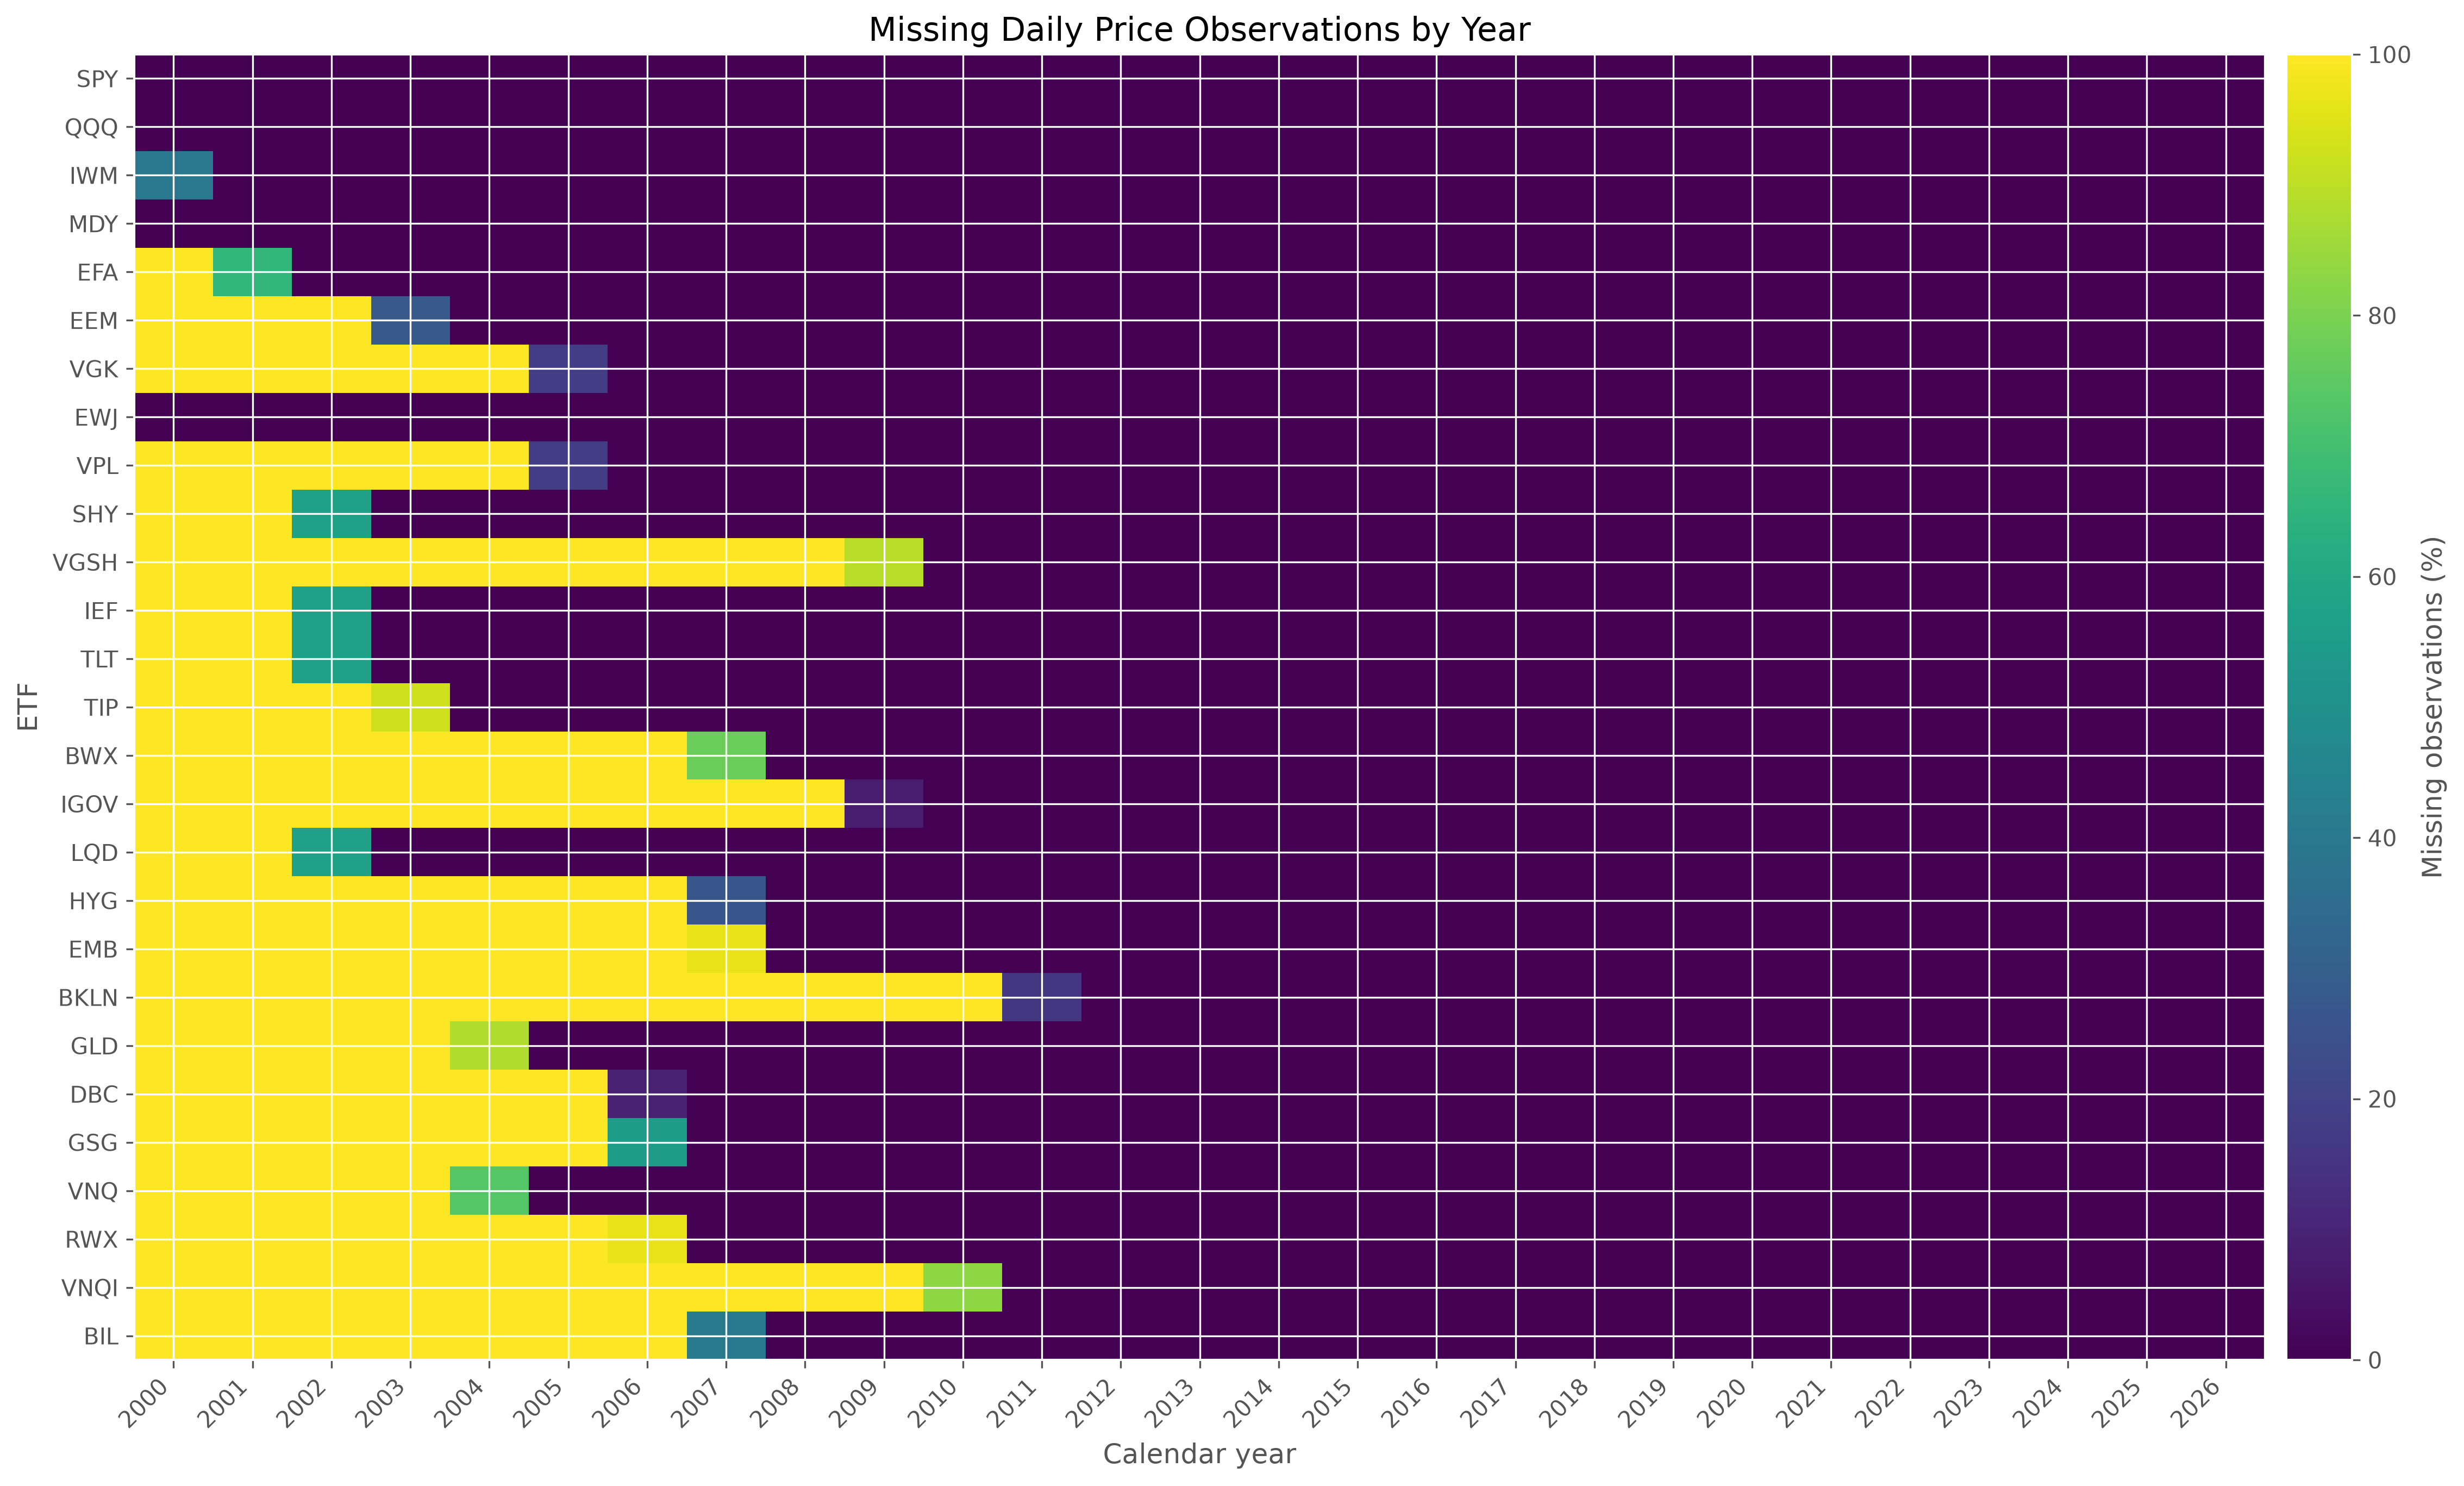

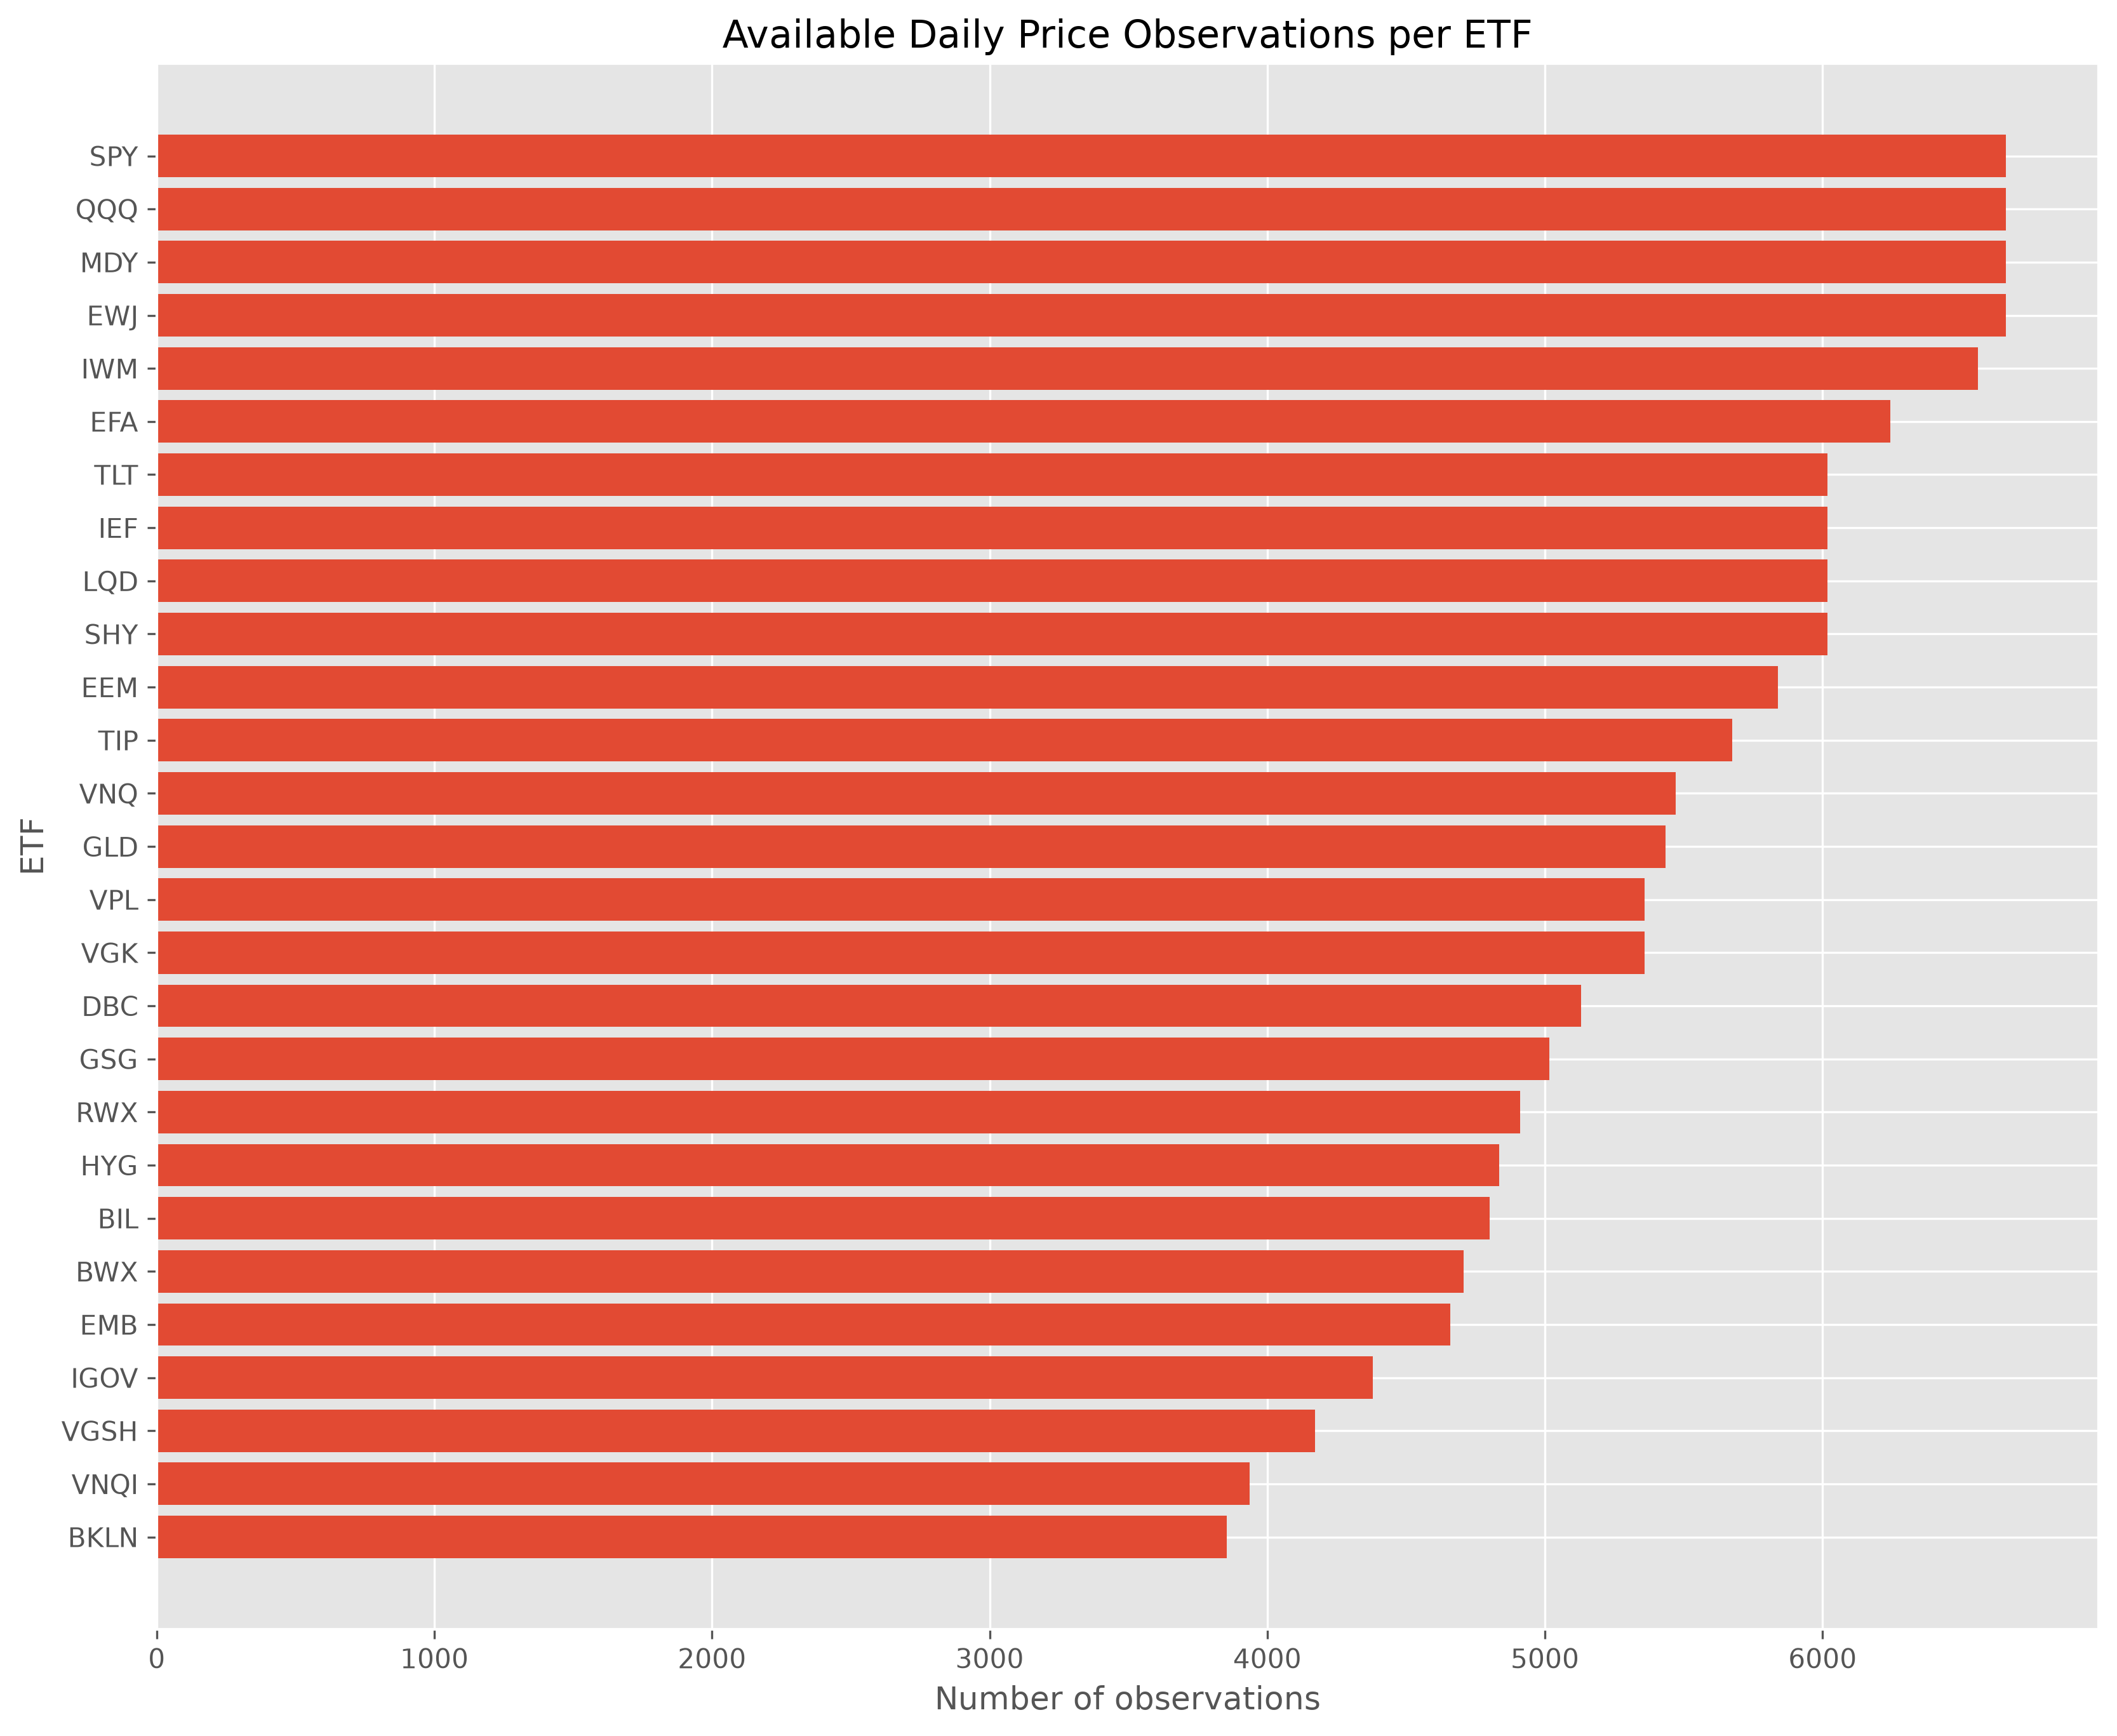

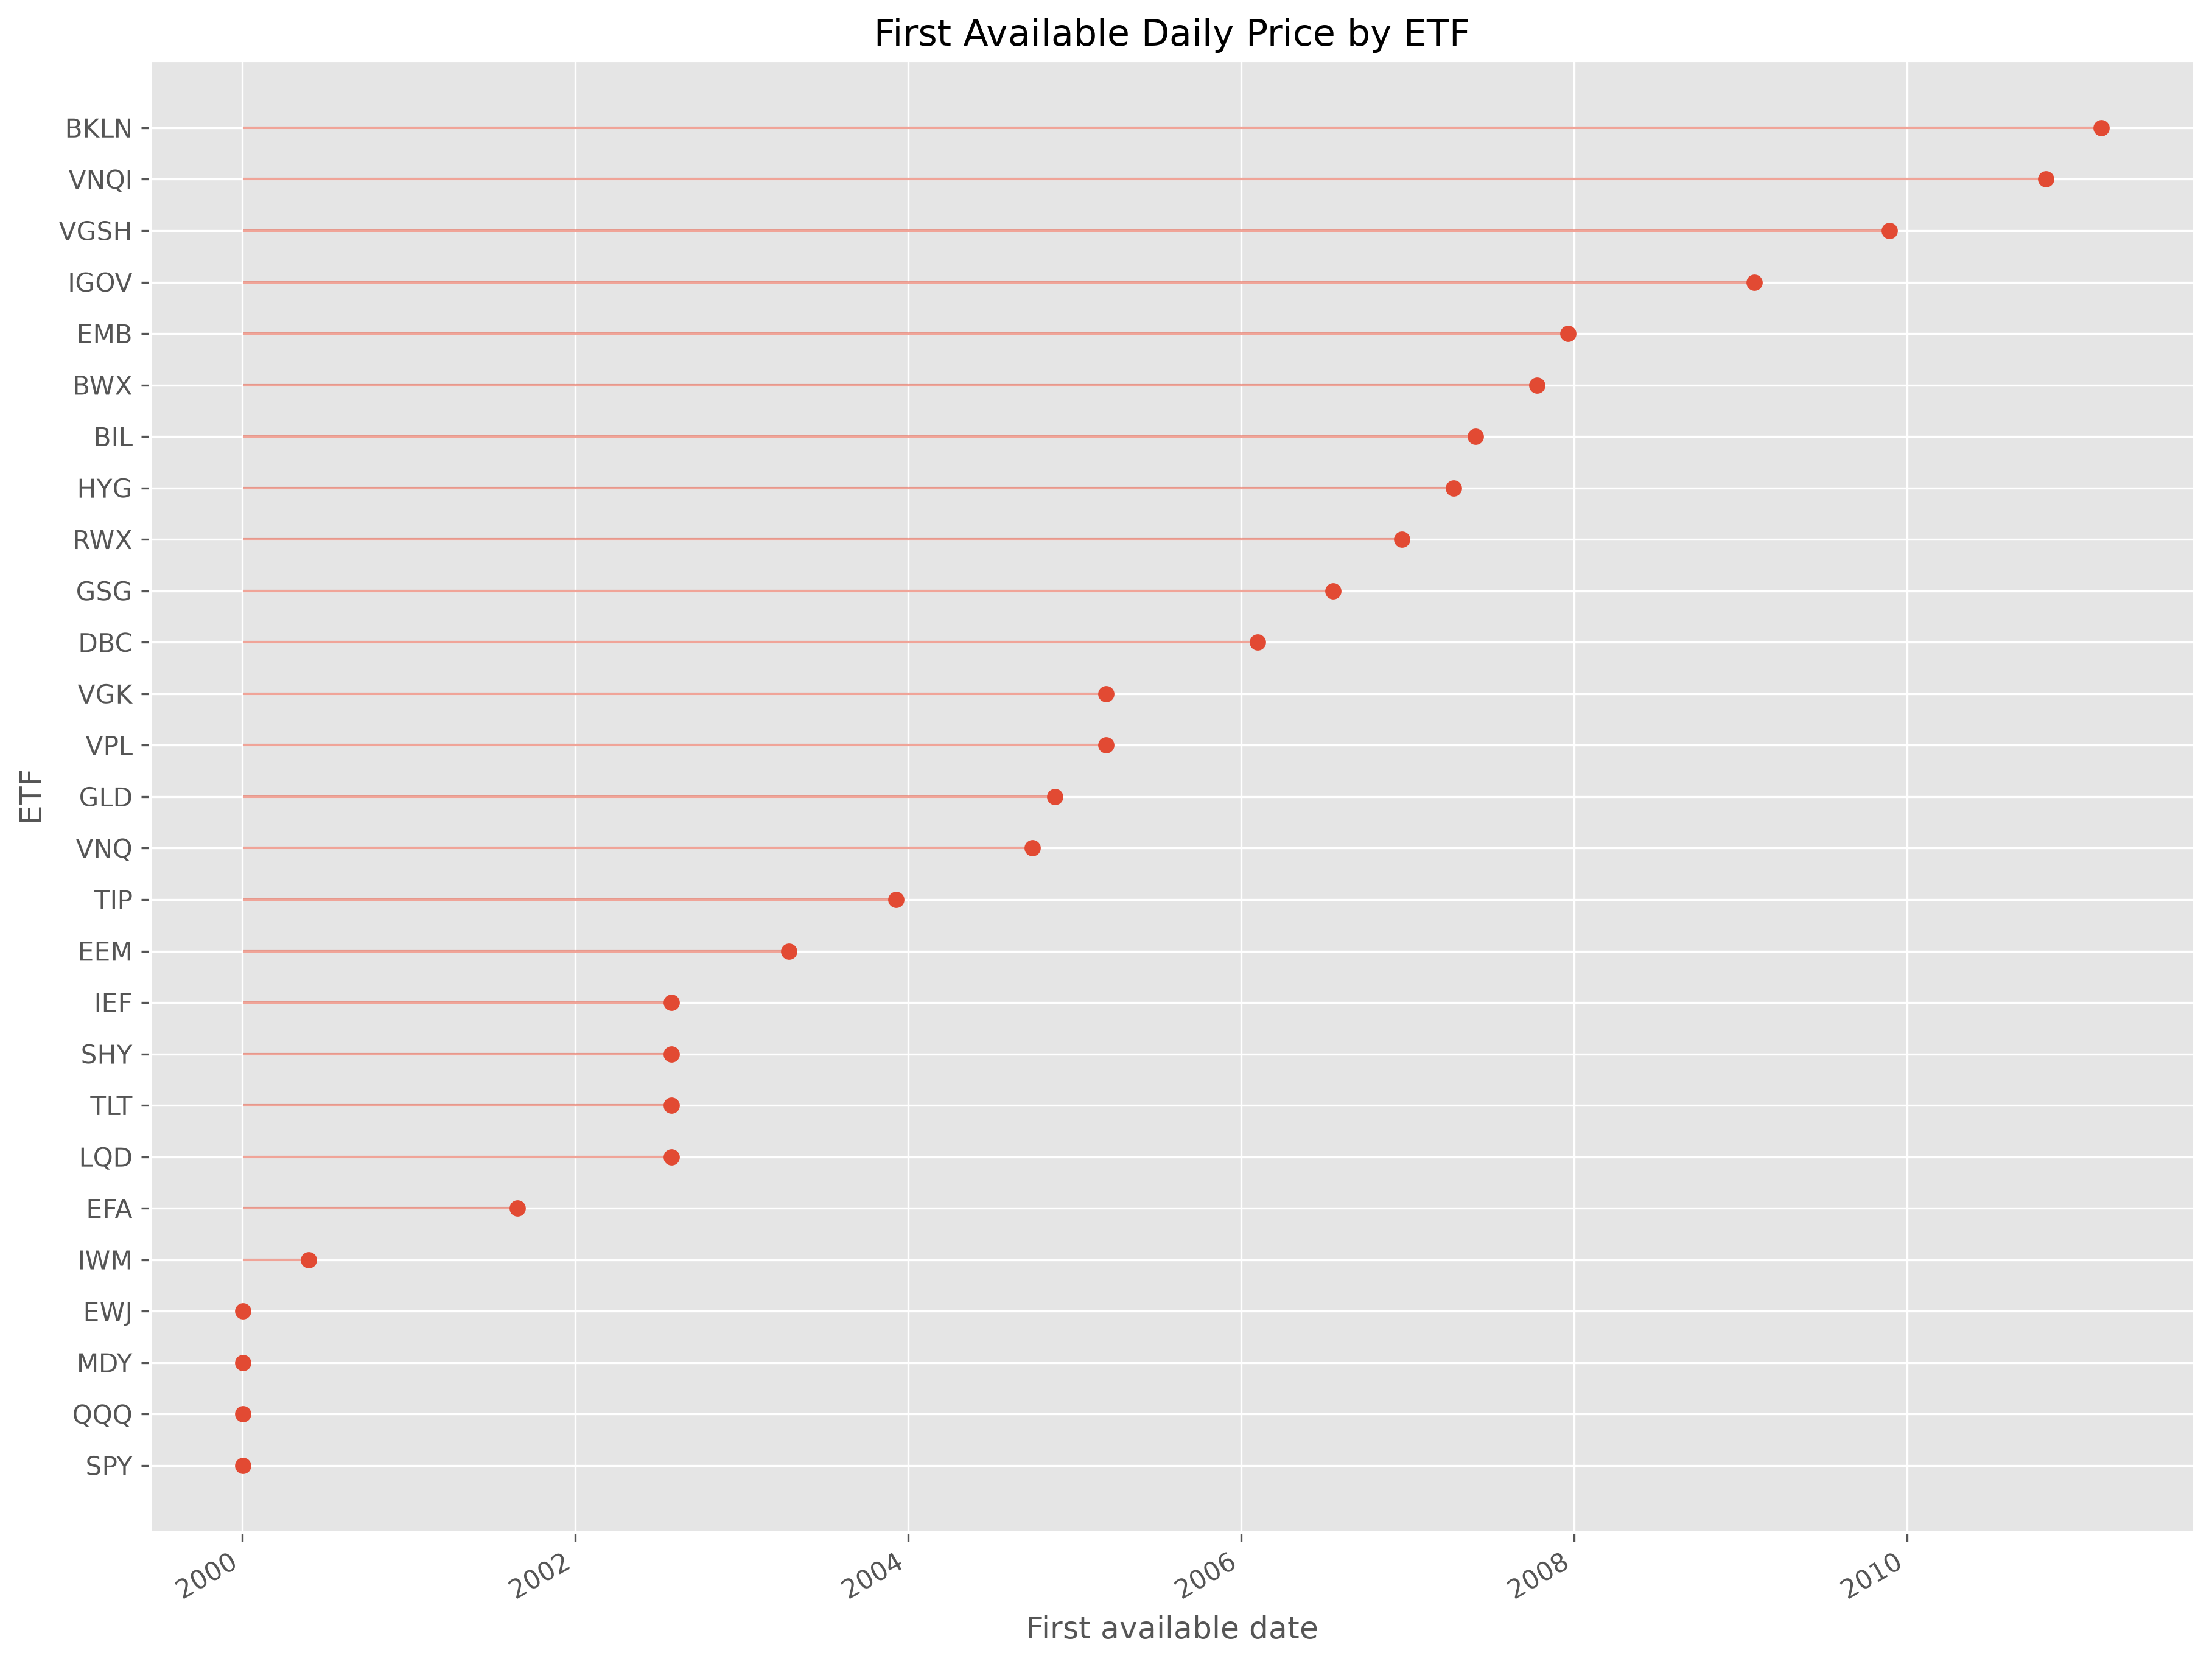

In [5]:
plot_paths = create_quality_plots(daily_prices, quality_report, missing_by_year)
for title, path in plot_paths.items():
    print(title.replace('_', ' ').title())
    display(Image(filename=str(path)))

## Discussion of late-inception ETFs

The configured universe does not have a single common inception date. Missing observations before an ETF's first valid price represent unavailable pre-inception history rather than tradable zero returns. The sample policy therefore defines a 23-ETF core universe that preserves the 2008 crisis period and a later 27-ETF data-policy panel. No ETF history is backfilled or synthetically created.
